# Quantum Harmonic Oscillator
This project starts by considering a quadratic potential $V(x)=\frac{1}{2}kx^2=\frac{1}{2}\omega^2x^2$ where $\omega = \sqrt{\frac{k}{m}}$


In [82]:
#import the following
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc
import math as ma


(-3.0, 3.0)

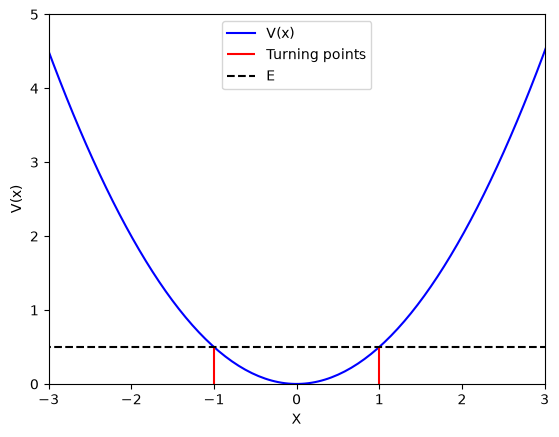

In [94]:
#set up our potentiaL

#lets start off dimensionless
hbar = 1
k = 1
m = 1
w = 1

#define the quantum energy levels
def E(n,w):
    return hbar*w*(n + 1/2)

w = np.sqrt(k/m)
x = np.linspace(-10, 10, 500)

#note the w in the function in case we change its value later
def V(x,w):
    V = (1/2)*(w**2)*(x**2)
    return V

turning_x = np.sqrt((2*E(0,w))/k)

fig,ax = plt.subplots()
ax.plot(x,V(x,w), 'b', label='V(x)')
ax.vlines([-turning_x, turning_x], 0, V(turning_x,w), 'r', label='Turning points')
ax.hlines(E(0,w), -12, 12,  'k', ls='--', label=r'E')
ax.legend()

ax.set_xlabel(r'X')
ax.set_ylabel(r'V(x)')
ax.set_ylim(0,5)
ax.set_xlim(-3,3)

## Setup
For the classical case the particle in the well is confined to regions where its $E\ge V_0$. The turning points for energy $E_0$ are shown on the above graph in red $-\sqrt{\frac{2E}{k}} \le x \le \sqrt{\frac{2E}{k}}$

However, in QM the energy levels are quantised and are seperated by $E_n = \hbar\omega(n + \frac{1}{2})$
In order to represent the possible eigenfunctions $\psi_n(x)$ we can use an analytical route using the known Hermite polynomials or a numerical route which will be discussed later on.

First we define a characteristic length $x_0 = \sqrt{\frac{\hbar}{m\omega}}$ and work with a dimensionless coordinate $a = \frac{x}{x_0}$.
This means: <br>
-The potential becomes $V(a) = \frac{1}{2}a^2$ <br>
-The exact energies are $E'_n = n + \frac{1}{2}$
-The dimensionless Hamiltonian is $\hat{H'} = \frac{\hat{H}}{{\hbar\omega}} = -\frac{1}{2}\frac{d^2}{da^2} + \frac{1}{2}a^2$

In [78]:
#implement this
x0 = np.sqrt(hbar/(m*w))
a = x/x0
#for now a = x due to our choices of constants and w

# Analytical approach
For the QHO, the eigenfunctions are known: $$\psi_n(x) = \left(\frac{1}{\sqrt{2^nn!}}\right)\left(\frac{1}{\pi^{\frac{1}{4}}x_0^{\frac{1}{2}}}\right)H_n\left(\frac{x}{x_0}\right)\exp\left(-\frac{x}{x_0}\right) $$
Thus we can use Scipy to find the Hermite polynomials and plot the wavefunctions of the first 6 energy levels.

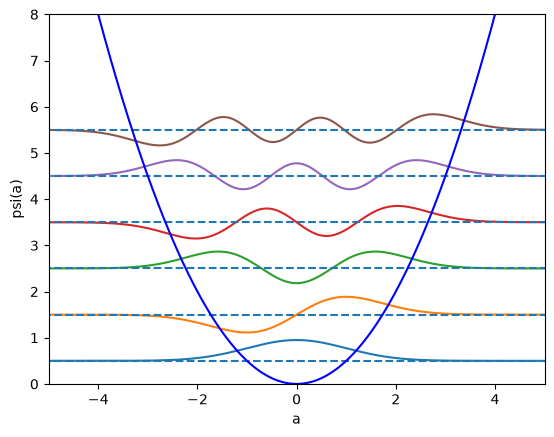

In [118]:
fig, ax = plt.subplots()
set_psi = []


for N in range(6):
    H = sc.special.eval_hermite(N, a)
    psi_n = H * (1/np.sqrt((2**N)*ma.factorial(N))) * ((1/(np.pi)**(1/4))) * np.exp(-a**2 / 2)
    set_psi.append(psi_n)

for M, psi_n in enumerate(set_psi):
    ax.plot(a, E(M,w) + 0.6*set_psi[M])
    ax.hlines([E(M,w)], -12, 12 , ls='--')

ax.plot(x,V(x,w), 'b', label='V(x)')
ax.set_xlabel(r'a')
ax.set_ylabel(r'psi(a)')
ax.set_ylim(0,8)
ax.set_xlim(-5,5)


plt.show()

We can also easily plot $|\psi|^2$:

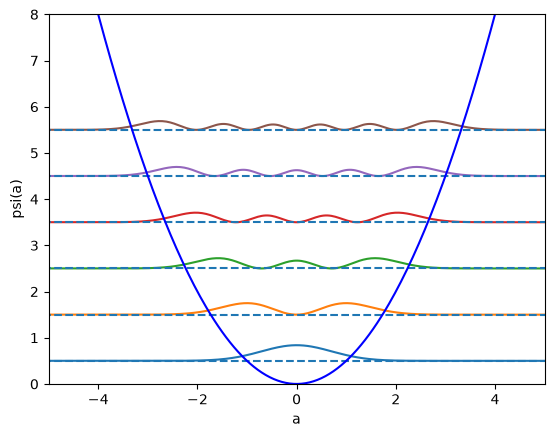

In [121]:
fig, ax = plt.subplots()

for M, psi_n in enumerate(set_psi):
    ax.plot(a, E(M,w) + 0.6*np.abs(set_psi[M])**2)
    ax.hlines([E(M,w)], -12, 12 , ls='--')

ax.plot(x,V(x,w), 'b', label='V(x)')
ax.set_xlabel(r'a')
ax.set_ylabel(r'psi(a)')
ax.set_ylim(0,8)
ax.set_xlim(-5,5)


plt.show()